# Forecasting Atmospheric CO₂ Concentration at Mauna Loa using SARIMA
**Applied Time Series (ATS) — Course End Mini Project**

**Objective.** Model the monthly concentration of carbon dioxide (CO₂) in the atmosphere, measured at the
Mauna Loa Observatory (Hawaii) since 1958, and forecast it for the coming years using a Box–Jenkins
time series model. The final model is deployed as an interactive Streamlit web app.

**Why this dataset?** CO₂ is the main greenhouse gas behind climate change, and the Mauna Loa record
(the *Keeling Curve*) is the longest continuous direct measurement of it. The series has a strong upward
**trend** and a regular yearly **seasonal cycle**, so every step of the time series workflow gives a
meaningful result.

| Step | Section |
|---|---|
| 1 | Data collection |
| 2 | Exploratory data analysis (line graph, scatter plot, histogram, QQ plot, descriptive statistics) |
| 3 | Dealing with missing values |
| 4 | Checking stationarity (ADF test) |
| 5 | Transformations (log check, differencing) |
| 6 | Seasonality and seasonal decomposition |
| 7 | ACF and PACF plots |
| 8 | Identifying the model type (AR / MA / ARMA / ARIMA / SARIMA) |
| 9 | Identifying the lags |
| 10 | Model selection with AIC and BIC, diagnostics and evaluation |
| 11 | Deployment (`train.py` + Streamlit app `app.py`) |

In [1]:
import sys, time, itertools, warnings
from pathlib import Path

# make the project folder importable (works from the project root or notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.holtwinters import ExponentialSmoothing

from src.ts_utils import (NOAA_URL, RAW_PATH, PROCESSED_PATH, read_noaa_raw, load_co2,
                          adf_report, kpss_report, fit_sarima, evaluate)
from src.plot_style import apply_style, savefig, COLORS

warnings.filterwarnings("ignore")
apply_style()
pd.set_option("display.precision", 4)
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

## Step 1 — Data Collection

**Source:** NOAA Global Monitoring Laboratory — *Trends in Atmospheric Carbon Dioxide*, Mauna Loa monthly means
(`co2_mm_mlo.csv`), freely downloadable without login:
<https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv>

Data from March 1958 to April 1974 were collected by C. David Keeling (Scripps Institution of Oceanography);
NOAA has measured since May 1974. The file is downloaded once and saved in `data/raw/`, so the notebook
also runs offline.

In [2]:
# Download once; afterwards the notebook works offline from the saved copy
if not RAW_PATH.exists():
    import urllib.request
    RAW_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(NOAA_URL, RAW_PATH)
    print("Downloaded fresh data from NOAA")

raw = read_noaa_raw(RAW_PATH)
print(f"Observations : {len(raw)}")
print(f"Period       : {raw.index.min():%B %Y} to {raw.index.max():%B %Y}")
print(f"Frequency    : monthly ({raw.index.freqstr})")
raw.head()

Observations : 823
Period       : March 1958 to September 2026
Frequency    : monthly (MS)


,year,month,decimal date,average,deseasonalized,ndays,sdev,unc
date,,,,,,,,
1958-03-01,1958,3,1958.2027,315.71,314.44,-1,-9.99,-0.99
1958-04-01,1958,4,1958.2877,317.45,315.16,-1,-9.99,-0.99
1958-05-01,1958,5,1958.3699,317.51,314.69,-1,-9.99,-0.99
1958-06-01,1958,6,1958.4548,317.27,315.15,-1,-9.99,-0.99
1958-07-01,1958,7,1958.5370,315.87,315.20,-1,-9.99,-0.99


In [3]:
raw.tail()

,year,month,decimal date,average,deseasonalized,ndays,sdev,unc
date,,,,,,,,
2026-05-01,2026,5,2026.3750,432.34,429.05,19,0.64,0.28
2026-06-01,2026,6,2026.4583,431.43,429.00,19,0.27,0.12
2026-07-01,2026,7,2026.5417,429.13,428.74,21,0.61,0.26
2026-08-01,2026,8,2026.6250,427.55,429.48,17,0.38,0.18
2026-09-01,2026,9,2026.7083,426.07,429.55,18,0.51,0.23


In [4]:
raw.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 823 entries, 1958-03-01 to 2026-09-01
Freq: MS
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   year            823 non-null    int64  
 1   month           823 non-null    int64  
 2   decimal date    823 non-null    float64
 3   average         823 non-null    float64
 4   deseasonalized  823 non-null    float64
 5   ndays           823 non-null    int64  
 6   sdev            823 non-null    float64
 7   unc             823 non-null    float64
dtypes: float64(5), int64(3)
memory usage: 57.9 KB


**Columns**

| Column | Meaning |
|---|---|
| `year`, `month`, `decimal date` | time of the observation |
| `average` | **monthly mean CO₂ mole fraction in ppm (parts per million) — our target variable** |
| `deseasonalized` | NOAA's own seasonally adjusted value (not used — we do our own decomposition) |
| `ndays` | number of days with valid data in the month |
| `sdev`, `unc` | standard deviation of daily values and uncertainty of the monthly mean |

The time index was built from `year` + `month` and set to a regular month-start frequency (`MS`).

## Step 2 — Exploratory Data Analysis (EDA)

### 2.1 Line graph

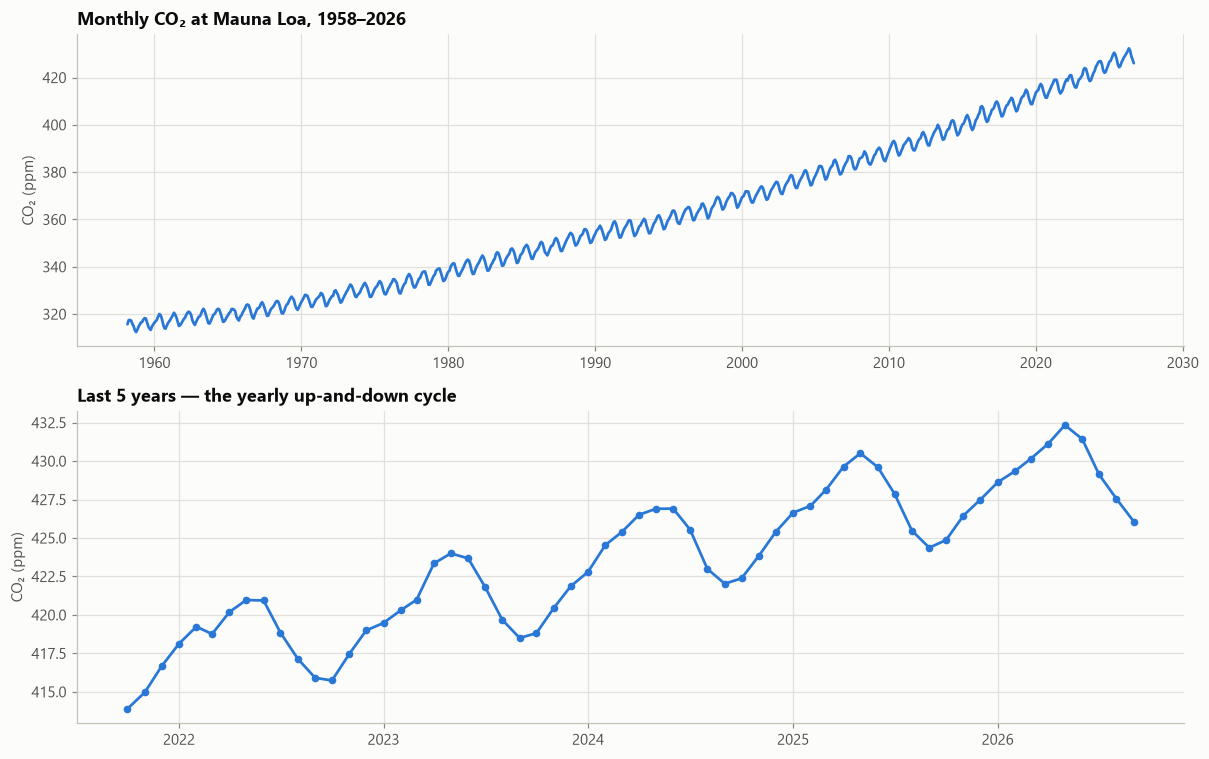

In [5]:
y = raw["average"].rename("co2")

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
axes[0].plot(y.index, y, color=COLORS["history"])
axes[0].set(title="Monthly CO₂ at Mauna Loa, 1958–2026", ylabel="CO₂ (ppm)")

recent = y[y.index > y.index.max() - pd.DateOffset(years=5)]
axes[1].plot(recent.index, recent, color=COLORS["history"], marker="o")
axes[1].set(title="Last 5 years — the yearly up-and-down cycle", ylabel="CO₂ (ppm)")
fig.tight_layout()
savefig(fig, "01_line_graph")
plt.show()

**Observations**
- A strong, steady **upward trend**: CO₂ has risen from about 315 ppm in 1958 to about 430 ppm today.
- The curve is slightly **bending upwards** — the rise is getting faster over time.
- A regular **saw-tooth yearly cycle** sits on top of the trend: CO₂ peaks around May and bottoms out
  around September–October every year (clearly visible in the 5-year zoom).
- No sudden jumps, outliers or breaks are visible.

### 2.2 Scatter plots

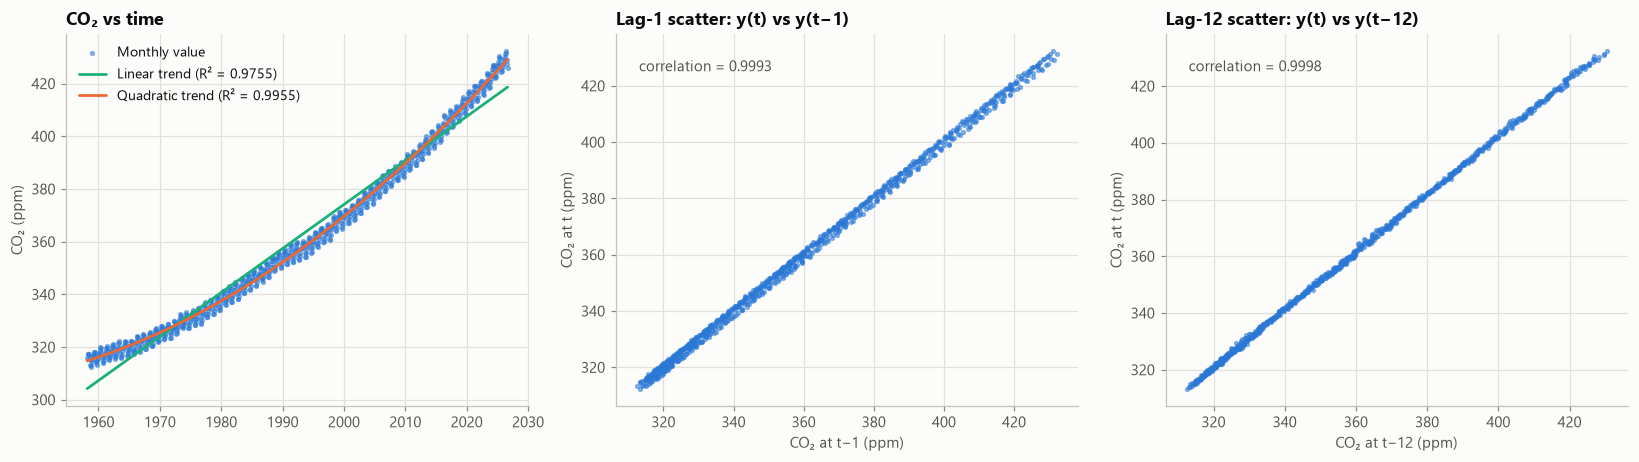

In [6]:
t = np.arange(len(y))
lin, quad = np.polyfit(t, y, 1), np.polyfit(t, y, 2)
r2 = lambda coef: 1 - np.sum((y - np.polyval(coef, t)) ** 2) / np.sum((y - y.mean()) ** 2)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].scatter(y.index, y, s=6, color=COLORS["history"], alpha=0.5, label="Monthly value")
axes[0].plot(y.index, np.polyval(lin, t), color=COLORS["third"], label=f"Linear trend (R² = {r2(lin):.4f})")
axes[0].plot(y.index, np.polyval(quad, t), color=COLORS["forecast"], label=f"Quadratic trend (R² = {r2(quad):.4f})")
axes[0].set(title="CO₂ vs time", ylabel="CO₂ (ppm)")
axes[0].legend(loc="upper left")

for ax, lag in zip(axes[1:], [1, 12]):
    ax.scatter(y.shift(lag), y, s=6, color=COLORS["history"], alpha=0.5)
    ax.set(title=f"Lag-{lag} scatter: y(t) vs y(t−{lag})", xlabel=f"CO₂ at t−{lag} (ppm)", ylabel="CO₂ at t (ppm)")
    ax.text(0.05, 0.9, f"correlation = {y.autocorr(lag):.4f}", transform=ax.transAxes, color=COLORS["ink2"])

fig.tight_layout()
savefig(fig, "02_scatter_plots")
plt.show()

**Observations**
- **CO₂ vs time:** a quadratic curve fits better than a straight line, confirming the trend is accelerating.
- **Lag plots:** the points lie almost exactly on a straight line — each month's value is extremely strongly
  correlated with the previous month and with the same month last year. This strong memory is exactly what
  time series models (AR/MA terms) exploit.

### 2.3 Histograms

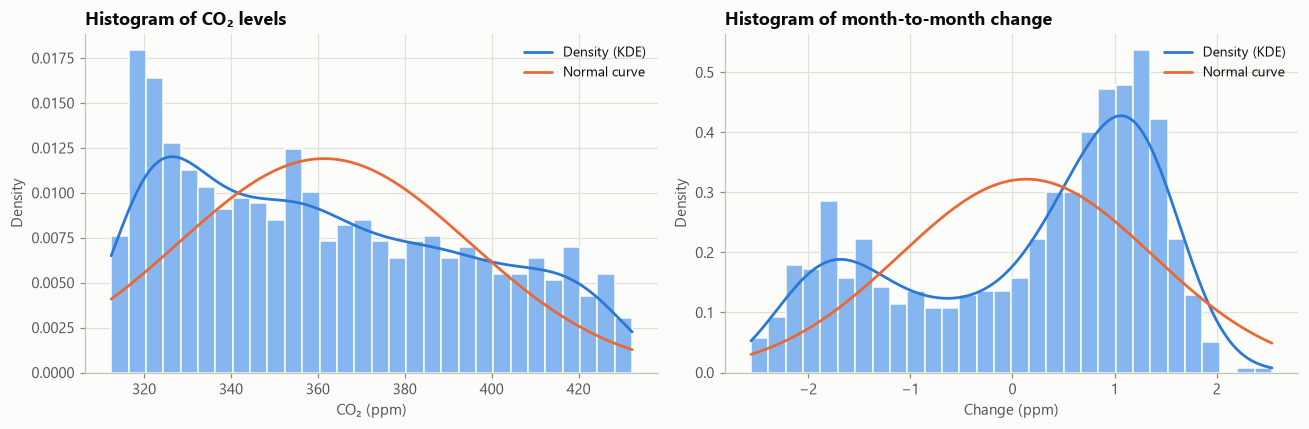

In [7]:
d1_preview = y.diff().dropna()

def hist_kde(ax, s, title, xlabel):
    ax.hist(s, bins=30, density=True, color="#86b6ef", edgecolor=COLORS["surface"], linewidth=1)
    xs = np.linspace(s.min(), s.max(), 300)
    ax.plot(xs, stats.gaussian_kde(s)(xs), color=COLORS["history"], label="Density (KDE)")
    ax.plot(xs, stats.norm.pdf(xs, s.mean(), s.std()), color=COLORS["forecast"], label="Normal curve")
    ax.set(title=title, xlabel=xlabel, ylabel="Density")
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
hist_kde(axes[0], y, "Histogram of CO₂ levels", "CO₂ (ppm)")
hist_kde(axes[1], d1_preview, "Histogram of month-to-month change", "Change (ppm)")
fig.tight_layout()
savefig(fig, "03_histograms")
plt.show()

**Observations**
- The **levels** are spread out and flat-topped (not bell-shaped): because of the trend, the values are not
  repeated draws from one distribution — a sign of non-stationarity.
- The **monthly changes** form a clearly two-humped shape: months where CO₂ rises (winter/spring) and
  months where it falls (summer/autumn) — the seasonal cycle again.

### 2.4 QQ plots

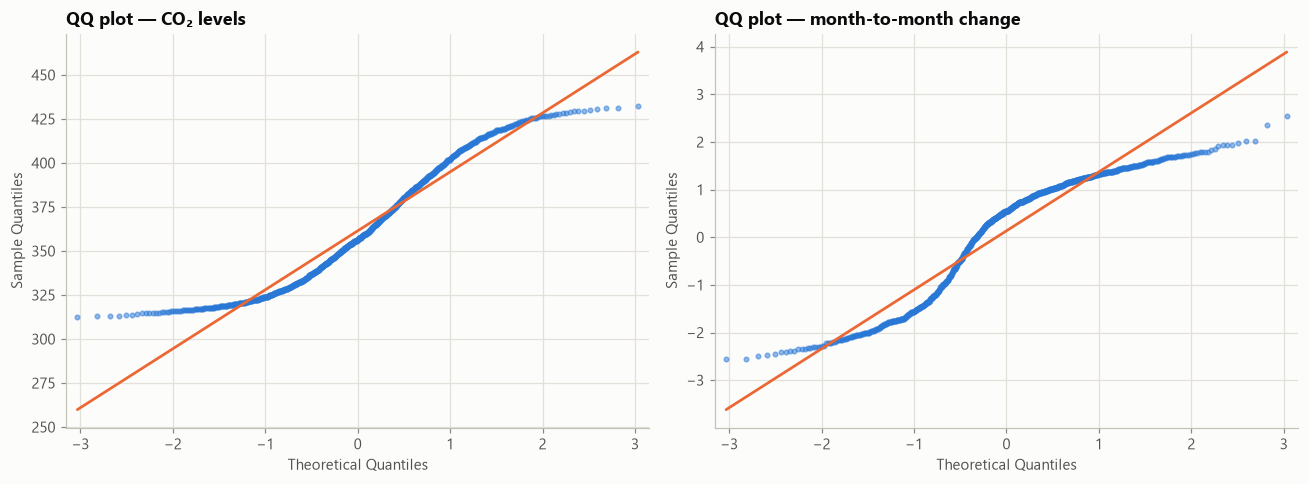

,Shapiro-Wilk p-value,Jarque-Bera p-value,Skewness,Excess kurtosis
CO₂ levels,9.7690e-18,5.0299e-13,0.3806,-1.0354
Month-to-month change,6.9343e-22,4.0150e-18,-0.5810,-0.9955


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, s, title in [(axes[0], y, "QQ plot — CO₂ levels"),
                     (axes[1], d1_preview, "QQ plot — month-to-month change")]:
    sm.qqplot(s, line="s", ax=ax, marker="o", markersize=3, alpha=0.5,
              markerfacecolor=COLORS["history"], markeredgecolor=COLORS["history"])
    ax.get_lines()[1].set(color=COLORS["forecast"], linewidth=1.8)
    ax.set_title(title)
fig.tight_layout()
savefig(fig, "04_qq_plots")
plt.show()

normality = pd.DataFrame({
    name: {"Shapiro-Wilk p-value": stats.shapiro(s).pvalue,
           "Jarque-Bera p-value": stats.jarque_bera(s).pvalue,
           "Skewness": s.skew(), "Excess kurtosis": s.kurt()}
    for name, s in [("CO₂ levels", y), ("Month-to-month change", d1_preview)]
}).T
normality

**Observations:** the points bend away from the straight reference line at both ends, and both normality tests
give p-values far below 0.05, so neither the levels nor the raw monthly changes are normally distributed.
This is expected for a trending, seasonal series. What matters later is that the **residuals of the final
model** look roughly normal (checked in Step 10).

### 2.5 Descriptive statistics

In [9]:
desc = y.describe()
desc["range"] = y.max() - y.min()
desc["skewness"] = y.skew()
desc["excess kurtosis"] = y.kurt()
desc["coefficient of variation (%)"] = y.std() / y.mean() * 100
desc.to_frame("CO₂ (ppm)")

,CO₂ (ppm)
count,823.0000
mean,361.4391
std,33.5118
min,312.4200
25%,331.2850
50%,356.3800
75%,387.8450
max,432.3400
range,119.9200
skewness,0.3806


In [10]:
# Decade-wise averages, using only complete calendar years
counts = y.groupby(y.index.year).size()
annual = y.groupby(y.index.year).mean()[counts == 12]
growth = annual.diff()
decades = pd.DataFrame({
    "Mean CO₂ (ppm)": annual.groupby(annual.index // 10 * 10).mean(),
    "Average yearly increase (ppm/year)": growth.groupby(growth.index // 10 * 10).mean(),
})
decades.index = [f"{d}s" for d in decades.index]
decades

,Mean CO₂ (ppm),Average yearly increase (ppm/year)
1950s,315.9817,NaN
1960s,320.2872,0.8639
1970s,330.8581,1.2214
1980s,345.6546,1.6370
1990s,360.5844,1.5335
2000s,378.7735,1.9102
2010s,400.4106,2.4007
2020s,420.3649,2.6167


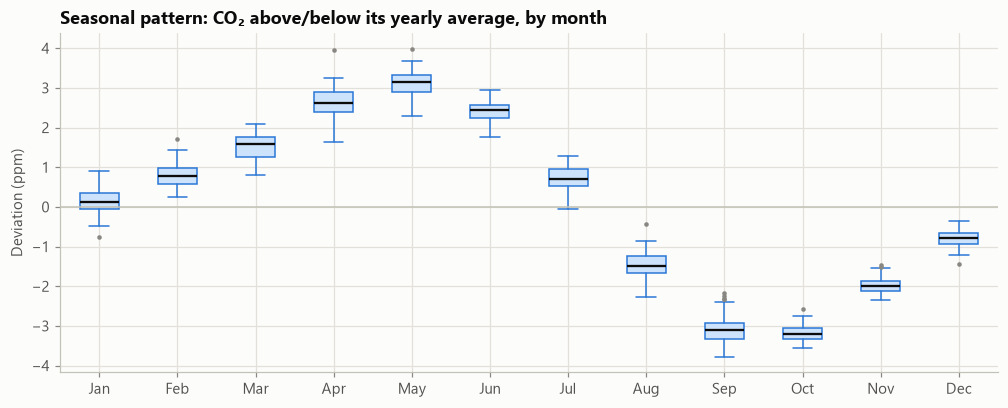

In [11]:
# Month-wise box plot of the detrended series (value minus its 12-month moving average)
detrended = (y - y.rolling(12, center=True).mean()).dropna()
by_month = [detrended[detrended.index.month == m].values for m in range(1, 13)]

fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot(by_month, tick_labels=MONTHS, patch_artist=True, widths=0.5,
           boxprops=dict(facecolor="#cde2fb", edgecolor=COLORS["history"]),
           medianprops=dict(color=COLORS["ink"], linewidth=1.5),
           whiskerprops=dict(color=COLORS["history"]), capprops=dict(color=COLORS["history"]),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=COLORS["muted"], markeredgecolor="none"))
ax.axhline(0, color=COLORS["axis"], linewidth=1)
ax.set(title="Seasonal pattern: CO₂ above/below its yearly average, by month", ylabel="Deviation (ppm)")
savefig(fig, "05_monthly_boxplot")
plt.show()

**Observations**
- The mean CO₂ level over the whole period is about 361 ppm, with a range of about 120 ppm.
- The **rate of increase has roughly tripled**: under 1 ppm/year in the 1960s versus about 2.5 ppm/year in the 2010s–2020s.
- The box plot shows a very consistent seasonal shape: CO₂ is **highest in May** and **lowest in
  September–October**. This is the "breathing" of the Northern Hemisphere's vegetation — plants absorb CO₂
  while growing in summer and release it as leaves decay in autumn and winter.

## Step 3 — Dealing with Missing Values

We check three things: (1) months missing from the date range, (2) empty (`NaN`) cells, and
(3) **sentinel codes** — NOAA writes negative numbers such as `-9.99` or `-1` instead of leaving a cell empty.

In [12]:
csv_rows = len(pd.read_csv(RAW_PATH, comment="#"))
expected_months = len(pd.date_range(raw.index.min(), raw.index.max(), freq="MS"))
print(f"Rows in file         : {csv_rows}")
print(f"Months in date range : {expected_months}")
print(f"Skipped months       : {expected_months - csv_rows}")
print()
print("Empty (NaN) cells per column:")
print(raw.isna().sum().to_string())

Rows in file         : 823
Months in date range : 823
Skipped months       : 0

Empty (NaN) cells per column:
year              0
month             0
decimal date      0
average           0
deseasonalized    0
ndays             0
sdev              0
unc               0


In [13]:
# NOAA uses negative numbers as "no data" codes instead of empty cells
codes = (raw[["average", "deseasonalized", "ndays", "sdev", "unc"]] < 0).sum()
codes.to_frame("Negative (code) values")

,Negative (code) values
average,0
deseasonalized,0
ndays,195
sdev,196
unc,194


In [14]:
# Scripps era (Mar 1958 – Apr 1974): no daily statistics were published
scripps = raw.loc[:"1974-04"]
print(f"Scripps-era months: {len(scripps)}, all with sdev < 0: {(scripps['sdev'] < 0).all()}")

# NOAA era: a negative sdev marks a month that NOAA filled in by interpolation
noaa = raw.loc["1974-05":]
noaa[noaa["sdev"] < 0][["average", "ndays", "sdev", "unc"]]

Scripps-era months: 194, all with sdev < 0: True


,average,ndays,sdev,unc
date,,,,
1975-12-01,330.77,-1,-9.99,0.0
1984-04-01,347.37,2,-9.99,0.0


**Findings**
- No months are skipped and there are **no empty cells**.
- The target column `average` has **no sentinel codes** — every month has a valid CO₂ value.
- The negative codes appear only in the helper columns `ndays`, `sdev` and `unc`: for the whole Scripps
  period (1958–1974, where daily statistics are not available) and for two NOAA months that NOAA itself
  filled by interpolation (shown above).
- Mauna Loa measurements were suspended after the **volcano eruption of November 2022**; from December 2022
  to July 2023 NOAA used a nearby site (Maunakea), so there is no gap in the series.

**Treatment:** replace the codes in the helper columns with `NaN` and drop those columns (they are not used
for modelling). The target is kept as `co2`. `load_co2()` in `src/ts_utils.py` would also turn any
non-positive value into `NaN` and fill it by **time interpolation**, so the pipeline stays safe if a future
download contains a gap.

In [15]:
clean = raw.copy()
helper_cols = ["ndays", "sdev", "unc"]
clean[helper_cols] = clean[helper_cols].where(clean[helper_cols] >= 0)
print("Missing values after converting codes to NaN:")
print(clean.isna().sum().to_string())

y = load_co2(RAW_PATH)            # the final, clean target series
assert y.isna().sum() == 0 and len(y) == expected_months
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
y.to_csv(PROCESSED_PATH)
print(f"\nClean series saved to {PROCESSED_PATH.relative_to(ROOT)} ({len(y)} months, 0 missing)")

Missing values after converting codes to NaN:
year                0
month               0
decimal date        0
average             0
deseasonalized      0
ndays             195
sdev              196
unc               194

Clean series saved to data\processed\co2_monthly.csv (823 months, 0 missing)


### 3.1 Demonstration on data with real gaps

Because our monthly series is complete, we demonstrate missing-value handling on the **weekly** Mauna Loa
CO₂ dataset bundled with `statsmodels` (1958–2001), which does contain gaps. To find the best method
fairly, we also **hide 100 known values on purpose**, fill them with each method and measure the error
against the true values.

In [16]:
weekly = sm.datasets.co2.load_pandas().data["co2"]
print(f"Weekly series: {len(weekly)} weeks, {weekly.isna().sum()} missing ({weekly.isna().mean():.1%})")

fill_methods = {
    "Mean fill": lambda s: s.fillna(s.mean()),
    "Forward fill": lambda s: s.ffill(),
    "Linear interpolation": lambda s: s.interpolate(method="linear"),
    "Cubic spline interpolation": lambda s: s.interpolate(method="spline", order=3),
}

# Hide 100 known values, fill them, and compare with the truth
rng = np.random.default_rng(42)
known = weekly.dropna().index[1:-1]
hidden = rng.choice(known, size=100, replace=False)
masked = weekly.copy()
masked[hidden] = np.nan
imputation = pd.DataFrame({
    name: evaluate(weekly[hidden], f(masked)[hidden]) for name, f in fill_methods.items()
}).T.sort_values("RMSE")
imputation

Weekly series: 2284 weeks, 59 missing (2.6%)


,MAE,RMSE,MAPE (%)
Linear interpolation,0.2150,0.3006,0.0630
Forward fill,0.3740,0.4611,0.1095
Cubic spline interpolation,0.8446,1.0414,0.2499
Mean fill,14.4542,16.2033,4.2280


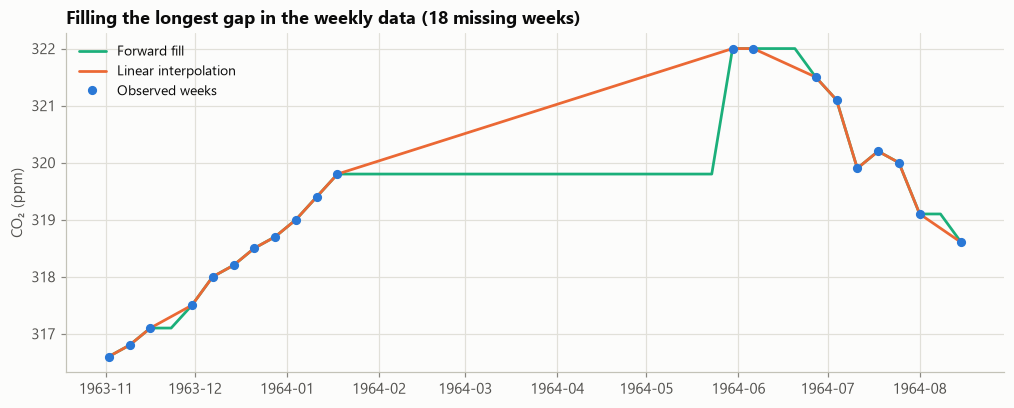

Weekly data (gaps filled) resampled to monthly vs NOAA monthly, 526 common months:
  correlation = 0.99994, mean absolute difference = 0.199 ppm


In [17]:
# Visual check around the longest real gap
is_na = weekly.isna()
run_id = (is_na != is_na.shift()).cumsum()          # consecutive equal values share an id
longest_run = is_na.groupby(run_id).sum().idxmax()  # run with the most missing weeks
gap = weekly.index[run_id == longest_run]
window = weekly[gap[0] - pd.Timedelta(weeks=12): gap[-1] + pd.Timedelta(weeks=12)]
linear_filled = weekly.interpolate(method="linear")[window.index]
ffill_filled = weekly.ffill()[window.index]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ffill_filled.index, ffill_filled, color=COLORS["third"], label="Forward fill")
ax.plot(linear_filled.index, linear_filled, color=COLORS["forecast"], label="Linear interpolation")
ax.plot(window.index, window, "o", color=COLORS["history"], markersize=5, label="Observed weeks")
ax.set(title=f"Filling the longest gap in the weekly data ({len(gap)} missing weeks)", ylabel="CO₂ (ppm)")
ax.legend()
savefig(fig, "06_missing_value_demo")
plt.show()

weekly_monthly = weekly.interpolate(method="linear").resample("MS").mean()
overlap = y.index.intersection(weekly_monthly.index)
print(f"Weekly data (gaps filled) resampled to monthly vs NOAA monthly, {len(overlap)} common months:")
print(f"  correlation = {np.corrcoef(y[overlap], weekly_monthly[overlap])[0, 1]:.5f}, "
      f"mean absolute difference = {np.mean(np.abs(y[overlap] - weekly_monthly[overlap])):.3f} ppm")

**Result**
- **Linear interpolation** is the most accurate method (RMSE ≈ 0.3 ppm), forward fill is clearly worse,
  and cubic spline interpolation overshoots between points. **Mean fill is useless** for a trending series —
  it puts a 1958–2001 average into every gap, giving errors of about 15 ppm.
- The plot shows the limit of simple methods: across a *long* gap (18 weeks in early 1964), a straight line
  cannot recreate the seasonal rise and fall. Short gaps are filled almost perfectly.
- After filling, the weekly data resampled to monthly almost exactly matches the NOAA monthly series.

Linear interpolation (`method="time"`, which is the same thing for evenly spaced dates) is therefore the method
built into `load_co2()`.

## Step 4 — Checking Stationarity

A **stationary** series has a constant mean, constant variance and an autocorrelation that depends only on
the lag. ARMA-type models require stationarity.

**Augmented Dickey–Fuller (ADF) test**
- $H_0$: the series has a unit root → **non-stationary**
- $H_1$: the series is stationary
- Reject $H_0$ (stationary) if p-value < 0.05.

As a cross-check we also run the **KPSS test**, whose hypotheses are the opposite
($H_0$: stationary). Agreement between both tests gives a reliable conclusion.

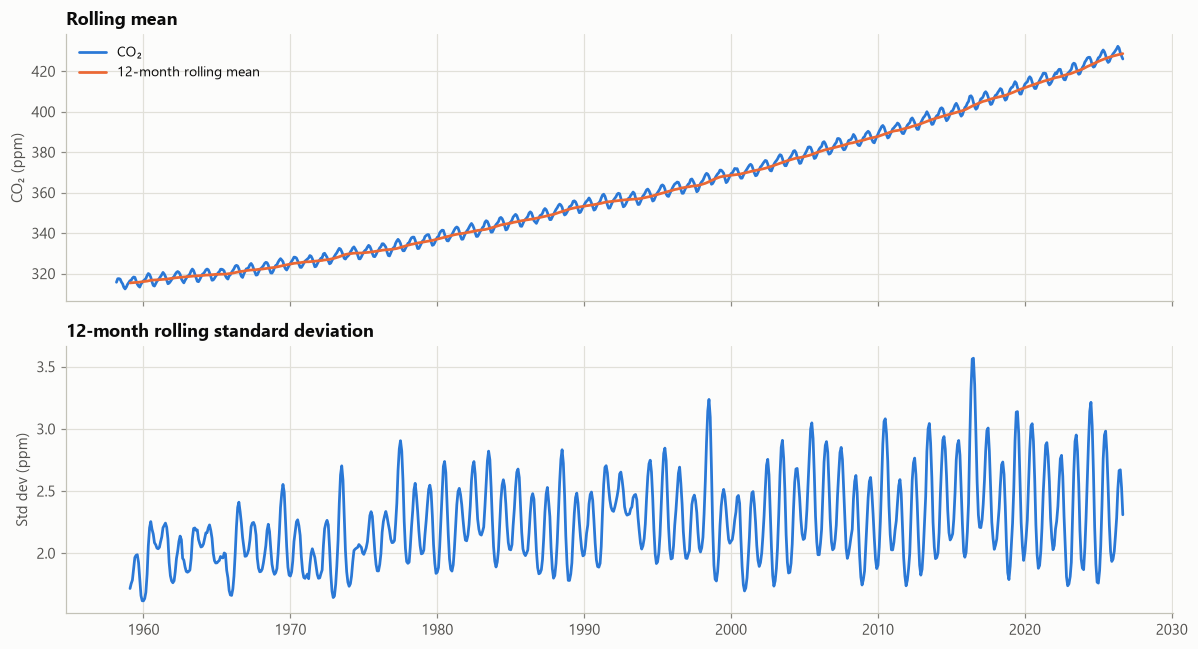

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(y.index, y, color=COLORS["history"], label="CO₂")
axes[0].plot(y.index, y.rolling(12).mean(), color=COLORS["forecast"], label="12-month rolling mean")
axes[0].set(title="Rolling mean", ylabel="CO₂ (ppm)")
axes[0].legend()
axes[1].plot(y.index, y.rolling(12).std(), color=COLORS["history"])
axes[1].set(title="12-month rolling standard deviation", ylabel="Std dev (ppm)")
fig.tight_layout()
savefig(fig, "07_rolling_statistics")
plt.show()

In [19]:
pd.concat([adf_report(y, "ADF — original series"), kpss_report(y, "KPSS — original series")], axis=1)

,ADF — original series,KPSS — original series
ADF statistic,5.9695,NaN
p-value,1.0,0.01
lags used,21,18
observations,801,NaN
critical 1%,-3.4385,NaN
critical 5%,-2.8652,0.463
verdict,Non-stationary,Non-stationary
KPSS statistic,NaN,4.356


**Result:** the rolling mean rises steadily (the mean is not constant). The ADF p-value is about 1.0, so we
**cannot reject** the unit-root hypothesis, and KPSS rejects stationarity. Both tests agree: the original
series is **non-stationary** and must be transformed before modelling.

## Step 5 — Transformations

### 5.1 Is a log / Box–Cox transform needed?
A log transform is used when the size of the fluctuations grows **in proportion** to the level of the series
(multiplicative behaviour). We check whether the yearly seasonal swing grows as CO₂ rises.

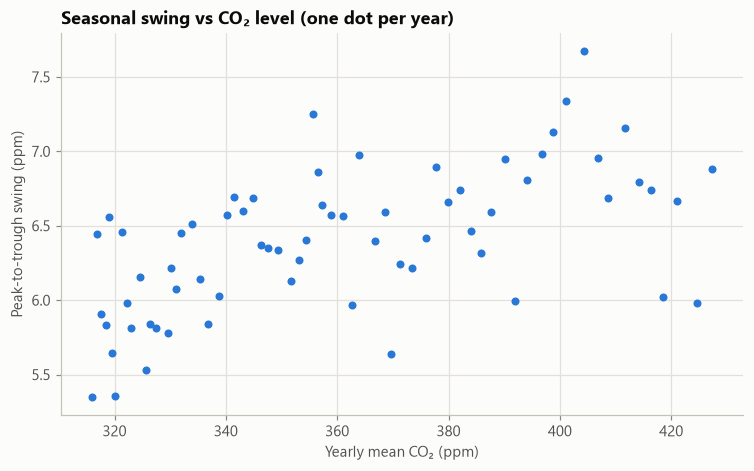

CO₂ level grew by           30%
Seasonal swing grew by      14%  (5.93 → 6.76 ppm)
Correlation of y and log(y) 0.99916


In [20]:
full_years = detrended.groupby(detrended.index.year).size() == 12
swing = detrended.groupby(detrended.index.year).agg(lambda s: s.max() - s.min())[full_years]
level = y.groupby(y.index.year).mean()[swing.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(level, swing, s=18, color=COLORS["history"])
ax.set(title="Seasonal swing vs CO₂ level (one dot per year)",
       xlabel="Yearly mean CO₂ (ppm)", ylabel="Peak-to-trough swing (ppm)")
savefig(fig, "08_swing_vs_level")
plt.show()

first, last = swing.iloc[:10].mean(), swing.iloc[-10:].mean()
print(f"CO₂ level grew by           {(level.iloc[-10:].mean() / level.iloc[:10].mean() - 1):.0%}")
print(f"Seasonal swing grew by      {(last / first - 1):.0%}  ({first:.2f} → {last:.2f} ppm)")
print(f"Correlation of y and log(y) {np.corrcoef(y, np.log(y))[0, 1]:.5f}")

**Result:** the seasonal swing grows far less than the level itself, and over this range `log(y)` is almost a
perfectly linear function of `y` (correlation ≈ 1). A log transform would change nothing meaningful, so the
series is modelled **without a log transform** (additive behaviour). The non-stationarity comes from the
**trend** and the **seasonality**, which are removed by **differencing**.

### 5.2 Differencing
- First difference (removes the trend): $\nabla y_t = y_t - y_{t-1}$  → order $d$
- Seasonal difference (removes the yearly pattern): $\nabla_{12} y_t = y_t - y_{t-12}$  → order $D$

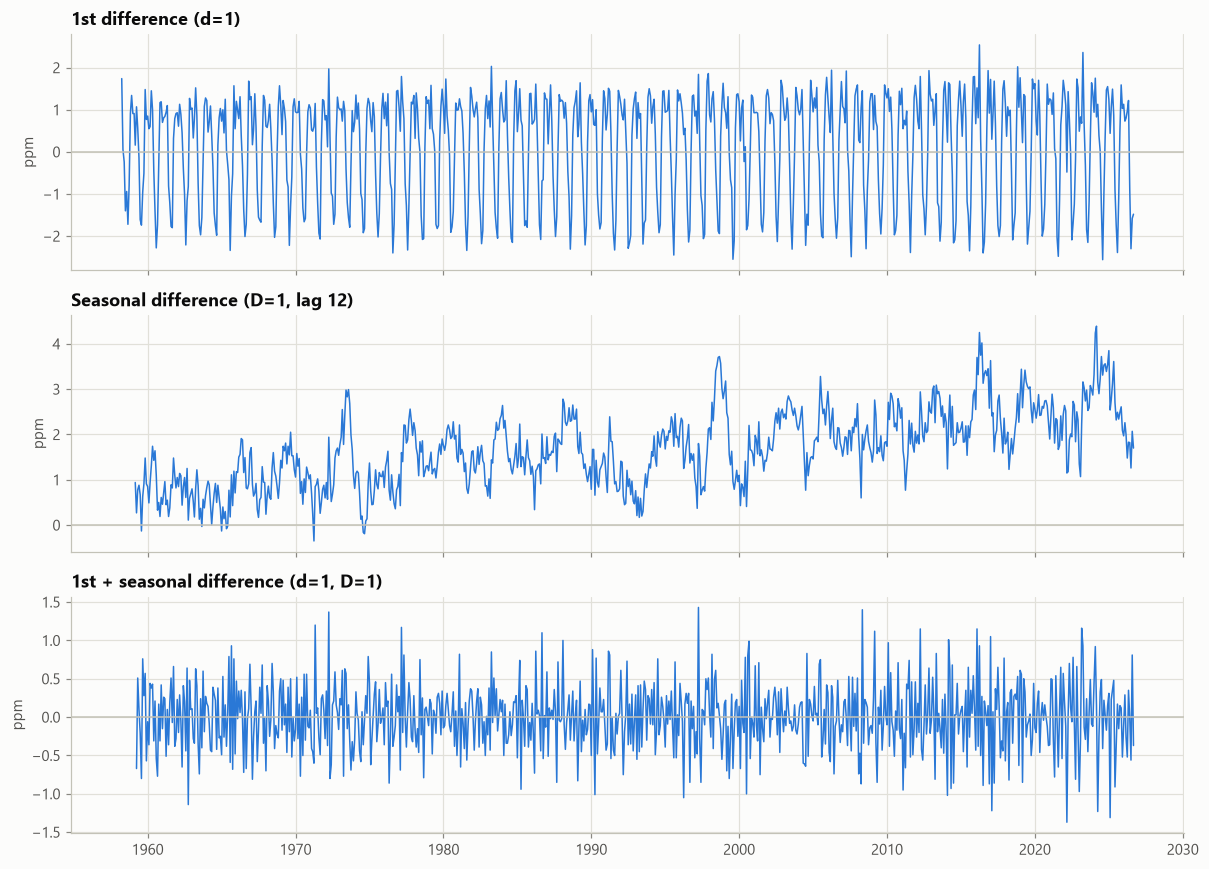

,ADF p-value,ADF verdict,KPSS p-value,KPSS verdict,Std dev (ppm)
Series,,,,,
Original,1.0000,Non-stationary,0.01,Non-stationary,33.5118
1st difference (d=1),0.0000,Stationary,0.10,Stationary,1.2388
"Seasonal difference (D=1, lag 12)",0.0033,Stationary,0.01,Non-stationary,0.8234
"1st + seasonal difference (d=1, D=1)",0.0000,Stationary,0.10,Stationary,0.4413


In [21]:
transformed = {
    "Original": y,
    "1st difference (d=1)": y.diff(),
    "Seasonal difference (D=1, lag 12)": y.diff(12),
    "1st + seasonal difference (d=1, D=1)": y.diff().diff(12),
}

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, (name, s) in zip(axes, list(transformed.items())[1:]):
    ax.plot(s.index, s, color=COLORS["history"], linewidth=1)
    ax.axhline(0, color=COLORS["axis"], linewidth=1)
    ax.set(title=name, ylabel="ppm")
fig.tight_layout()
savefig(fig, "09_differencing")
plt.show()

rows = []
for name, s in transformed.items():
    a, k = adf_report(s), kpss_report(s)
    rows.append({"Series": name, "ADF p-value": a["p-value"], "ADF verdict": a["verdict"],
                 "KPSS p-value": k["p-value"], "KPSS verdict": k["verdict"], "Std dev (ppm)": s.std()})
pd.DataFrame(rows).set_index("Series")

In [22]:
# Does the 1st difference still contain the yearly pattern? Look at its ACF at seasonal lags
acf_d1 = acf(y.diff().dropna(), nlags=48)
pd.Series({f"lag {k}": acf_d1[k] for k in (12, 24, 36, 48)}, name="ACF of 1st difference").to_frame()

,ACF of 1st difference
lag 12,0.9244
lag 24,0.9094
lag 36,0.8943
lag 48,0.8781


*(KPSS p-values are reported only between 0.01 and 0.10 — "0.01" means "0.01 or smaller", "0.1" means
"0.1 or larger".)*

**Choosing the differencing**
- **d = 1 only:** both tests call it stationary, but its autocorrelation at lags 12, 24, 36, 48 stays around
  0.9 and barely decays — the yearly pattern is still fully present (a *seasonal unit root*).
- **D = 1 only:** ADF says stationary but KPSS disagrees — the slowly changing growth rate is still left in.
- **d = 1 and D = 1:** both tests agree it is stationary, and the standard deviation drops to its lowest
  value. Over-differencing would *increase* the variance, so this is not over-differenced.

**Conclusion: d = 1, D = 1, seasonal period s = 12.** This stationary series is used for the ACF/PACF analysis.

In [23]:
stationary = y.diff().diff(12).dropna()
print(f"Stationary series: {len(stationary)} observations, mean = {stationary.mean():.4f} ppm")

Stationary series: 810 observations, mean = 0.0009 ppm


## Step 6 — Seasonality and Seasonal Decomposition

The series is split into **trend + seasonal + residual** (additive model, because the seasonal swing is
roughly constant — see Step 5.1):

$$y_t = T_t + S_t + R_t$$

We use classical decomposition (`seasonal_decompose`) and the more robust **STL** decomposition
(Seasonal-Trend decomposition using LOESS).

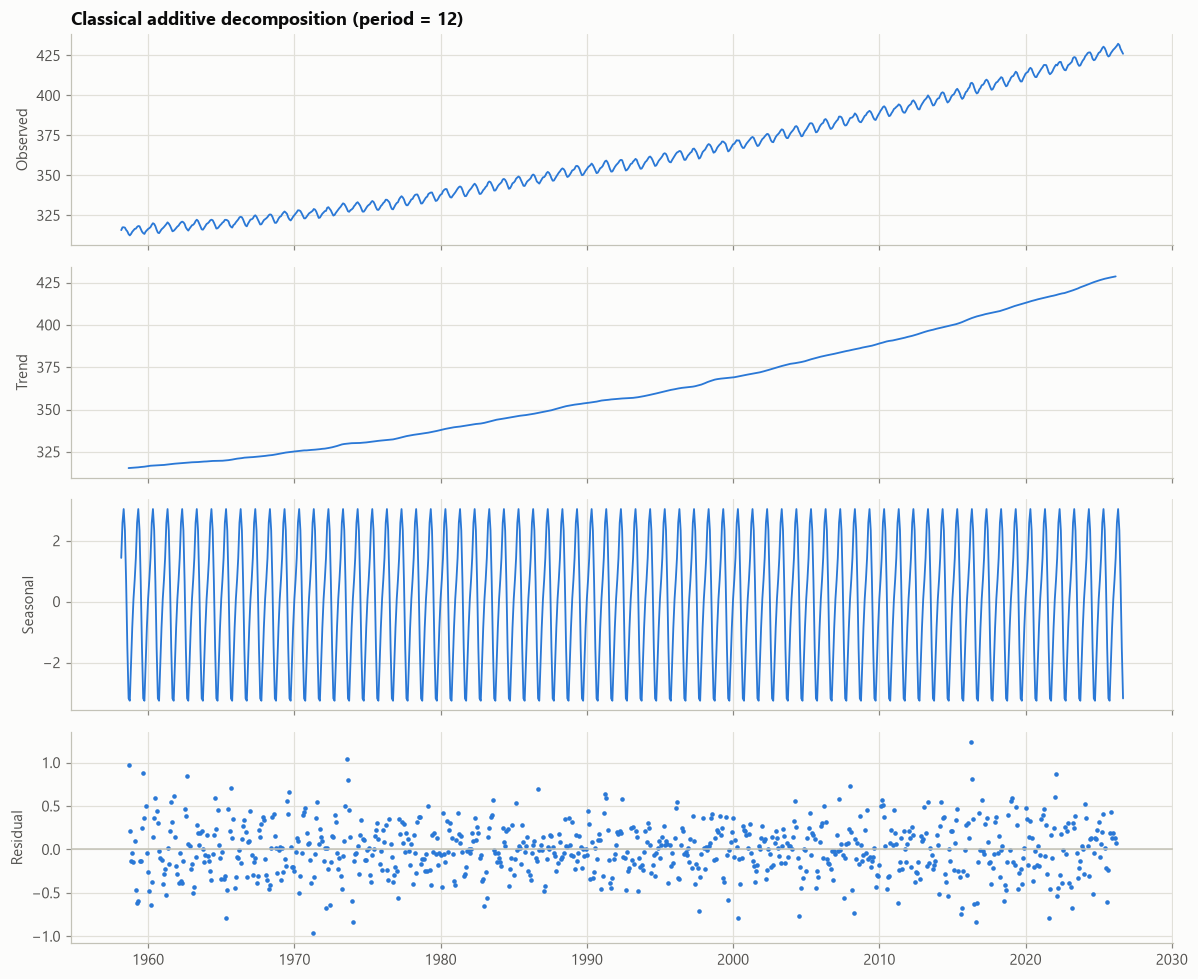

In [24]:
def plot_components(observed, trend, seasonal, resid, title, name):
    fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
    for ax, s, label in zip(axes[:3], [observed, trend, seasonal], ["Observed", "Trend", "Seasonal"]):
        ax.plot(s.index, s, color=COLORS["history"], linewidth=1.2)
        ax.set_ylabel(label)
    axes[3].scatter(resid.index, resid, s=4, color=COLORS["history"])
    axes[3].axhline(0, color=COLORS["axis"], linewidth=1)
    axes[3].set_ylabel("Residual")
    axes[0].set_title(title)
    fig.tight_layout()
    savefig(fig, name)
    plt.show()

classical = seasonal_decompose(y, model="additive", period=12)
plot_components(y, classical.trend, classical.seasonal, classical.resid,
                "Classical additive decomposition (period = 12)", "10_classical_decomposition")

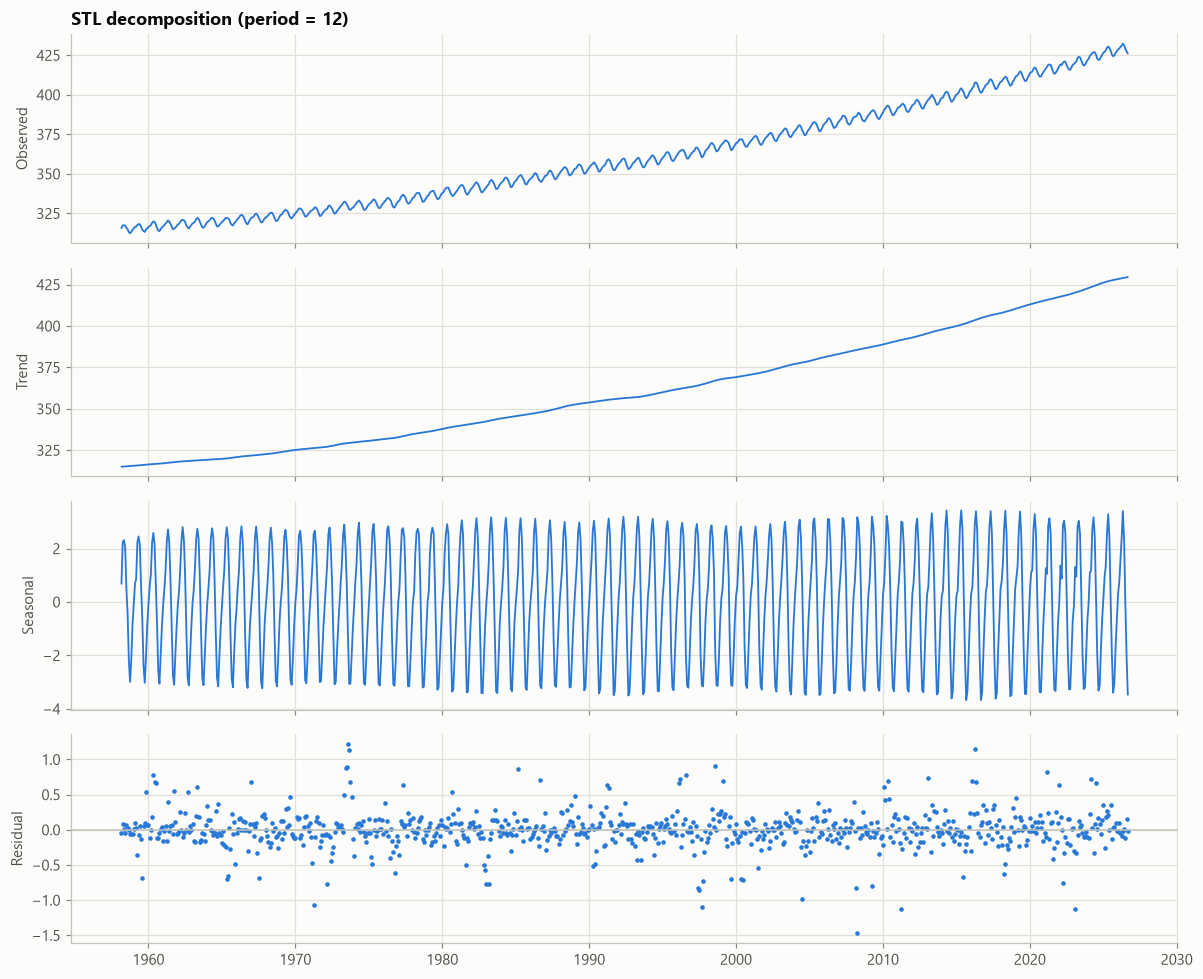

Strength of trend       F_T = 0.9999
Strength of seasonality F_S = 0.9841   (0 = none, 1 = very strong)


In [25]:
stl = STL(y, period=12, robust=True).fit()
plot_components(y, stl.trend, stl.seasonal, stl.resid, "STL decomposition (period = 12)", "11_stl_decomposition")

trend_strength = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
seasonal_strength = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
print(f"Strength of trend       F_T = {trend_strength:.4f}")
print(f"Strength of seasonality F_S = {seasonal_strength:.4f}   (0 = none, 1 = very strong)")

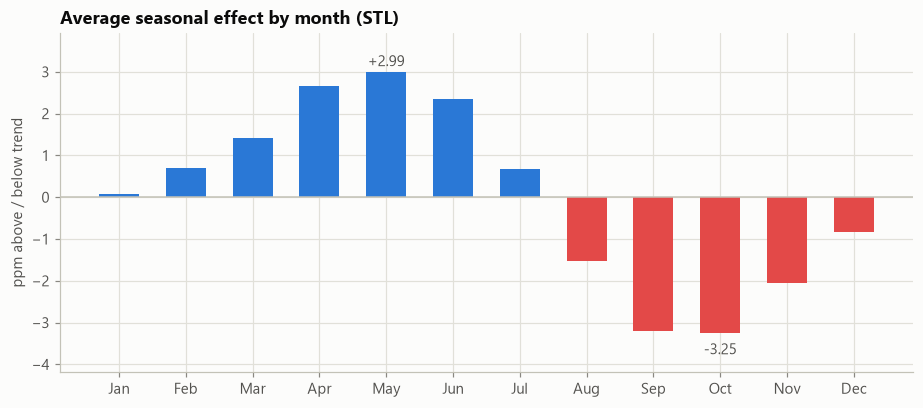

Peak month: May (+2.99 ppm), lowest month: Oct (-3.25 ppm)


In [26]:
profile = stl.seasonal.groupby(stl.seasonal.index.month).mean()
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(MONTHS, profile.values, width=0.6,
              color=[COLORS["history"] if v >= 0 else "#e34948" for v in profile.values])
ax.axhline(0, color=COLORS["axis"], linewidth=1)
for rect, v in zip(bars, profile.values):
    if v in (profile.max(), profile.min()):
        ax.annotate(f"{v:+.2f}", (rect.get_x() + rect.get_width() / 2, v),
                    xytext=(0, 4 if v > 0 else -14), textcoords="offset points", ha="center", color=COLORS["ink2"])
ax.margins(y=0.15)
ax.set(title="Average seasonal effect by month (STL)", ylabel="ppm above / below trend")
savefig(fig, "12_seasonal_profile")
plt.show()
print(f"Peak month: {MONTHS[profile.idxmax() - 1]} ({profile.max():+.2f} ppm), "
      f"lowest month: {MONTHS[profile.idxmin() - 1]} ({profile.min():+.2f} ppm)")

**Result**
- The **trend** component is a smooth, accelerating rise.
- The **seasonal** component repeats every 12 months, peaking in **May** and reaching its lowest point in
  **September–October**, a total swing of about 6–7 ppm.
- The **residual** is small and centred on zero, with no remaining pattern.
- Strength measures close to 1 confirm that both the trend and the seasonality are **very strong**.
  A seasonal model with period **s = 12** is required.

## Step 7 — ACF and PACF Plots

- **ACF (autocorrelation function):** correlation of the series with its own past values at each lag.
- **PACF (partial autocorrelation function):** correlation at a lag after removing the effect of the shorter lags.

Bars outside the shaded band (95% confidence, ±1.96/√n) are statistically significant.

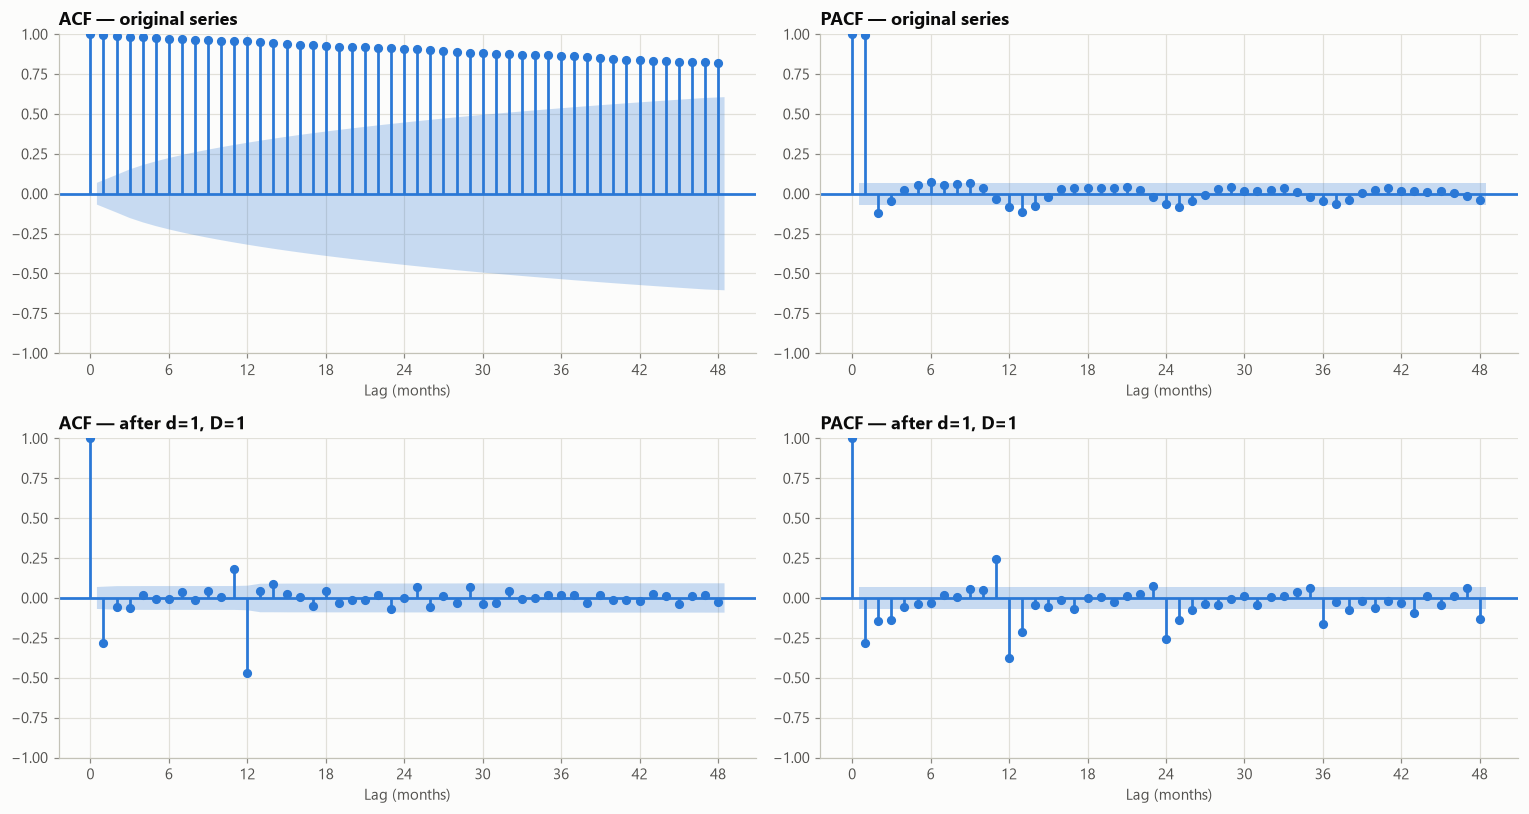

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))
for ax, plotter, s, title in [
    (axes[0, 0], plot_acf, y, "ACF — original series"),
    (axes[0, 1], plot_pacf, y, "PACF — original series"),
    (axes[1, 0], plot_acf, stationary, "ACF — after d=1, D=1"),
    (axes[1, 1], plot_pacf, stationary, "PACF — after d=1, D=1"),
]:
    kwargs = {"method": "ywm"} if plotter is plot_pacf else {}
    plotter(s, lags=48, ax=ax, title=title, color=COLORS["history"],
            vlines_kwargs={"colors": COLORS["history"]}, **kwargs)
    ax.set_xticks(range(0, 49, 6))
    ax.set_xlabel("Lag (months)")
fig.tight_layout()
savefig(fig, "13_acf_pacf")
plt.show()

In [28]:
bound = 1.96 / np.sqrt(len(stationary))
corr = pd.DataFrame({"ACF": acf(stationary, nlags=48), "PACF": pacf(stationary, nlags=48, method="ywm")}).iloc[1:]
corr.index.name = "lag"
print(f"Significance bound: ±{bound:.3f}")
corr[(corr.abs() > bound).any(axis=1)].round(3)

Significance bound: ±0.069


,ACF,PACF
lag,,
1,-0.282,-0.282
2,-0.055,-0.146
3,-0.063,-0.135
11,0.184,0.246
12,-0.470,-0.377
13,0.042,-0.213
14,0.089,-0.041
23,-0.069,0.075
24,-0.001,-0.259


**Reading the plots**
- **Original series:** the ACF decays extremely slowly from almost 1 — the classic signature of a
  non-stationary (trending) series. This confirms the need for differencing.
- **Differenced series (d=1, D=1):**
  - **ACF:** one significant negative spike at **lag 1** (−0.28) and one large negative spike at **lag 12**
    (−0.47), then it *cuts off* — lag 24 is essentially zero. The positive spike at lag 11, right next to the
    seasonal lag, is a side-effect of combining a lag-1 and a lag-12 term (a multiplicative seasonal model
    produces spikes beside lag 12). A few other bars (lags 14, 23, 29) only just touch the band, which is
    expected by chance when 48 lags are tested at 95% confidence.
  - **PACF:** *tails off* — decaying spikes at lags 1, 2, 3 and at the seasonal lags 12, 24, 36, 48.

## Step 8 — Identifying the Model Type

| Model | Suitable? | Reason |
|---|---|---|
| AR(p) | ✗ | needs a stationary series; our series has a trend and seasonality |
| MA(q) | ✗ | needs a stationary series |
| ARMA(p, q) | ✗ | needs a stationary series |
| ARIMA(p, d, q) | partly | handles the trend through $d$, but cannot model the yearly pattern |
| **SARIMA(p, d, q)(P, D, Q)ₛ** | **✓** | handles the trend ($d=1$) **and** the yearly seasonality ($D=1$, $s=12$) |

**Identification rules (Box–Jenkins)**

| Pattern | ACF | PACF |
|---|---|---|
| AR(p) | tails off | cuts off after lag p |
| MA(q) | cuts off after lag q | tails off |
| ARMA(p, q) | tails off | tails off |

Applied to our differenced series:
- **Non-seasonal part:** ACF cuts off after lag 1, PACF tails off → **MA(1)**, so $q = 1$, $p = 0$.
- **Seasonal part:** ACF cuts off after lag 12 (one seasonal lag), PACF tails off at 12, 24, 36 →
  **seasonal MA(1)**, so $Q = 1$, $P = 0$.

The ACF/PACF analysis points to **SARIMA(0,1,1)(0,1,1)₁₂** — the well-known *airline model*.

## Step 9 — Identifying the Lags

The plots give a starting point, but neighbouring orders can fit almost as well. The PACF also shows small
spikes at lags 2 and 3, so small AR terms are worth testing. We therefore build a **candidate grid** around
the identified orders and let the information criteria (Step 10) decide:

| Term | Meaning | Values tried |
|---|---|---|
| p | non-seasonal AR lags | 0, 1, 2 |
| d | non-seasonal differencing | 1 (from Step 5) |
| q | non-seasonal MA lags | 0, 1, 2 |
| P | seasonal AR lags (multiples of 12) | 0, 1 |
| D | seasonal differencing | 1 (from Step 5) |
| Q | seasonal MA lags (multiples of 12) | 0, 1 |
| s | seasonal period | 12 |

That gives 3 × 3 × 2 × 2 = **36 candidate models**.

In [29]:
p_values, q_values, P_values, Q_values = [0, 1, 2], [0, 1, 2], [0, 1], [0, 1]
candidates = list(itertools.product(p_values, q_values, P_values, Q_values))
print(f"{len(candidates)} candidate SARIMA models")

36 candidate SARIMA models


## Step 10 — Model Selection with AIC and BIC

- **AIC** (Akaike Information Criterion) $= 2k - 2\ln L$
- **BIC** (Bayesian Information Criterion) $= k\ln n - 2\ln L$

Here $L$ is the likelihood, $k$ the number of parameters and $n$ the number of observations. Both reward a good
fit and penalise extra parameters — **lower is better**. BIC penalises extra parameters more strongly, so it
prefers simpler models.

### 10.1 Train / test split
The last **36 months** are held back as a test set. Models are selected on the training data only, and the test
set is used to check real forecasting accuracy.

Train: Mar 1958 – Sep 2023  (787 months)
Test : Oct 2023 – Sep 2026  (36 months)


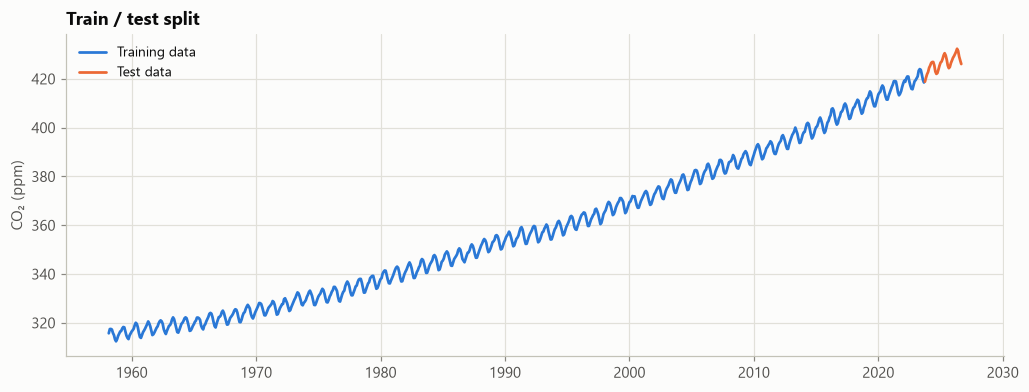

In [30]:
TEST_MONTHS = 36
train, test = y.iloc[:-TEST_MONTHS], y.iloc[-TEST_MONTHS:]
print(f"Train: {train.index.min():%b %Y} – {train.index.max():%b %Y}  ({len(train)} months)")
print(f"Test : {test.index.min():%b %Y} – {test.index.max():%b %Y}  ({len(test)} months)")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(train.index, train, color=COLORS["history"], label="Training data")
ax.plot(test.index, test, color=COLORS["forecast"], label="Test data")
ax.set(title="Train / test split", ylabel="CO₂ (ppm)")
ax.legend()
savefig(fig, "14_train_test_split")
plt.show()

### 10.2 Grid search over the candidate models

In [31]:
results = []
start = time.time()
for p, q, P, Q in candidates:
    res = fit_sarima(train, (p, 1, q), (P, 1, Q, 12))
    results.append({"Model": f"SARIMA({p},1,{q})({P},1,{Q})12", "order": (p, 1, q),
                    "seasonal_order": (P, 1, Q, 12), "Parameters": len(res.params),
                    "AIC": res.aic, "BIC": res.bic, "Converged": res.mle_retvals.get("converged", True)})
print(f"Fitted {len(results)} models in {time.time() - start:.0f} seconds")

grid = pd.DataFrame(results)
grid["AIC rank"] = grid["AIC"].rank().astype(int)
grid["BIC rank"] = grid["BIC"].rank().astype(int)
grid.drop(columns=["order", "seasonal_order"]).to_csv(ROOT / "reports" / "model_selection.csv", index=False)
grid.sort_values("AIC").head(10).drop(columns=["order", "seasonal_order"]).set_index("Model")

Fitted 36 models in 57 seconds


,Parameters,AIC,BIC,Converged,AIC rank,BIC rank
Model,,,,,,
"SARIMA(1,1,1)(0,1,1)12",4,424.6745,443.2808,True,1,2
"SARIMA(2,1,1)(0,1,1)12",5,425.5524,448.8103,True,2,4
"SARIMA(1,1,2)(0,1,1)12",5,425.8890,449.1468,True,3,5
"SARIMA(0,1,2)(0,1,1)12",4,426.2450,444.8513,True,4,3
"SARIMA(1,1,1)(1,1,1)12",5,426.6729,449.9307,True,5,7
"SARIMA(2,1,2)(0,1,1)12",6,426.9174,454.8268,True,6,9
"SARIMA(2,1,1)(1,1,1)12",6,427.5518,455.4612,True,7,10
"SARIMA(1,1,2)(1,1,1)12",6,427.8881,455.7975,True,8,11
"SARIMA(0,1,2)(1,1,1)12",5,428.2448,451.5027,True,9,8


In [32]:
grid.sort_values("BIC").head(5).drop(columns=["order", "seasonal_order"]).set_index("Model")

,Parameters,AIC,BIC,Converged,AIC rank,BIC rank
Model,,,,,,
"SARIMA(0,1,1)(0,1,1)12",3,428.5648,442.5195,True,10,1
"SARIMA(1,1,1)(0,1,1)12",4,424.6745,443.2808,True,1,2
"SARIMA(0,1,2)(0,1,1)12",4,426.2450,444.8513,True,4,3
"SARIMA(2,1,1)(0,1,1)12",5,425.5524,448.8103,True,2,4
"SARIMA(1,1,2)(0,1,1)12",5,425.8890,449.1468,True,3,5


The best models under both criteria share the seasonal part **(0,1,1)₁₂** (one seasonal MA term, no seasonal AR
term), but the criteria pick different non-seasonal parts: AIC prefers SARIMA(1,1,1)(0,1,1)₁₂, BIC prefers the
simpler SARIMA(0,1,1)(0,1,1)₁₂. When AIC and BIC disagree we compare the top candidates of both
on the things that matter for forecasting: **accuracy on the unseen test data** and **white-noise residuals**
(Ljung–Box test, $H_0$: residuals are uncorrelated — we want p > 0.05).

In [33]:
shortlist = pd.concat([grid.nsmallest(3, "AIC"), grid.nsmallest(3, "BIC")]).drop_duplicates("Model")
rows = []
for _, m in shortlist.iterrows():
    res = fit_sarima(train, m["order"], m["seasonal_order"])
    fc = res.get_forecast(TEST_MONTHS)
    ci = fc.conf_int(alpha=0.05)
    lb = acorr_ljungbox(res.resid.iloc[13:], lags=[12, 24])   # skip the first 13 start-up residuals
    rows.append({"Model": m["Model"], "Parameters": m["Parameters"], "AIC": m["AIC"], "BIC": m["BIC"],
                 **evaluate(test, fc.predicted_mean),
                 "95% interval coverage": ((test >= ci.iloc[:, 0]) & (test <= ci.iloc[:, 1])).mean(),
                 "Ljung-Box p (lag 12)": lb["lb_pvalue"].iloc[0],
                 "Ljung-Box p (lag 24)": lb["lb_pvalue"].iloc[1]})
comparison = pd.DataFrame(rows).set_index("Model").sort_values("RMSE")
comparison

,Parameters,AIC,BIC,MAE,RMSE,MAPE (%),95% interval coverage,Ljung-Box p (lag 12),Ljung-Box p (lag 24)
Model,,,,,,,,,
"SARIMA(0,1,1)(0,1,1)12",3,428.5648,442.5195,0.9162,1.0118,0.2147,0.9722,0.4786,0.6298
"SARIMA(0,1,2)(0,1,1)12",4,426.2450,444.8513,0.9348,1.0300,0.2191,0.9444,0.8899,0.8091
"SARIMA(1,1,1)(0,1,1)12",4,424.6745,443.2808,0.9594,1.0539,0.2248,0.9167,0.9800,0.8694
"SARIMA(1,1,2)(0,1,1)12",5,425.8890,449.1468,0.9839,1.0780,0.2306,0.8611,0.9963,0.9096
"SARIMA(2,1,1)(0,1,1)12",5,425.5524,448.8103,0.9887,1.0827,0.2317,0.8333,0.9987,0.9259


### 10.3 Final model choice

**SARIMA(0,1,1)(0,1,1)₁₂** is selected because it
1. has the **lowest BIC** of all 36 models, and its AIC is within about 4 points of the best,
2. is the **simplest** model (only 2 coefficients + the noise variance) — the principle of parsimony,
3. gives the **most accurate forecasts on the test data** among the shortlisted models,
4. has white-noise residuals (Ljung–Box p > 0.05), and its 95% prediction interval contains 35 of the 36 test months,
5. is exactly the model suggested by the ACF/PACF analysis in Step 8.

The AIC-best model adds an AR(1) term that improves the in-sample fit slightly but does not forecast better.

In [34]:
best = grid.loc[grid["BIC"].idxmin()]
ORDER, SEASONAL_ORDER = best["order"], best["seasonal_order"]
print(f"Selected model: {best['Model']}")
model_train = fit_sarima(train, ORDER, SEASONAL_ORDER)
print(model_train.summary())

Selected model: SARIMA(0,1,1)(0,1,1)12


                                     SARIMAX Results                                      
Dep. Variable:                                co2   No. Observations:                  787
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -211.282
Date:                            Mon, 26 Oct 2026   AIC                            428.565
Time:                                    21:48:43   BIC                            442.519
Sample:                                03-01-1958   HQIC                           433.934
                                     - 09-01-2023                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3842      0.032    -12.036      0.000      -0.447      -0.322
ma.S.L12      -0.8648      0.020   

**Fitted model equation** (with $B$ the backshift operator, $B y_t = y_{t-1}$):

$$(1 - B)(1 - B^{12})\, y_t = (1 + \theta_1 B)(1 + \Theta_1 B^{12})\, \varepsilon_t$$

with $\theta_1 \approx -0.38$ (non-seasonal MA) and $\Theta_1 \approx -0.86$ (seasonal MA), both highly significant
(p < 0.001). In words: this month's change in yearly growth depends on last month's surprise and the surprise
from the same month last year.

### 10.4 Residual diagnostics

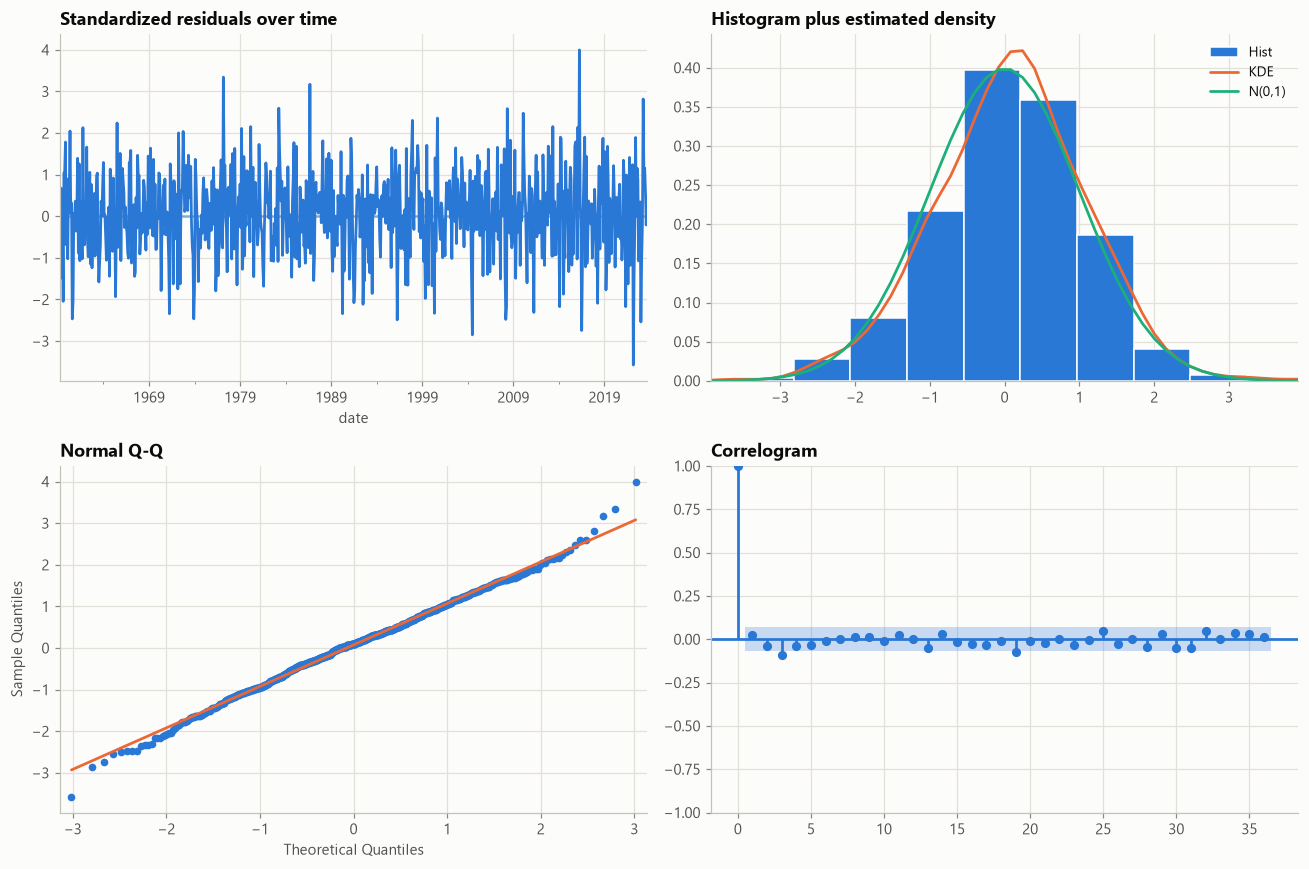

,lb_stat,lb_pvalue,Residuals are white noise?
lag,,,
6,11.0850,0.0858,Yes
12,11.5964,0.4786,Yes
24,21.1514,0.6298,Yes
36,33.9475,0.5666,Yes


In [35]:
fig = model_train.plot_diagnostics(figsize=(12, 8), lags=36)
fig.axes[0].set_title("Standardized residuals over time")
fig.axes[2].get_lines()[1].set(color=COLORS["forecast"], linewidth=1.8)   # QQ reference line
fig.tight_layout()
savefig(fig, "15_residual_diagnostics")
plt.show()

resid = model_train.resid.iloc[13:]
lb = acorr_ljungbox(resid, lags=[6, 12, 24, 36])
lb["Residuals are white noise?"] = np.where(lb["lb_pvalue"] > 0.05, "Yes", "No")
lb.index.name = "lag"
lb

**Result:** the standardised residuals fluctuate randomly around zero with no pattern, the histogram is close to a
normal curve, the QQ plot follows the line apart from a few extreme months, and the correlogram shows no
significant autocorrelation. The Ljung–Box p-values are all above 0.05, so the residuals are **white noise** —
the model has captured all of the predictable structure.

### 10.5 Forecast accuracy on the test set
We compare SARIMA with three simple baselines:
- **Seasonal naive:** next year = the same month last year.
- **Seasonal naive + drift:** same month last year + the average yearly increase.
- **Holt–Winters:** exponential smoothing with additive trend and seasonality.

In [36]:
forecast = model_train.get_forecast(TEST_MONTHS)
sarima_pred, sarima_ci = forecast.predicted_mean, forecast.conf_int(alpha=0.05)

last_year = train.iloc[-12:].values
yearly_increase = (train.iloc[-12:].values - train.iloc[-24:-12].values).mean()
years_ahead = np.repeat(np.arange(1, TEST_MONTHS // 12 + 1), 12)
baselines = {
    "Seasonal naive": pd.Series(np.tile(last_year, TEST_MONTHS // 12), index=test.index),
    "Seasonal naive + drift": pd.Series(np.tile(last_year, TEST_MONTHS // 12) + yearly_increase * years_ahead,
                                        index=test.index),
    "Holt-Winters": ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12)
                    .fit().forecast(TEST_MONTHS),
}
scores = pd.DataFrame({f"{best['Model']} (selected)": evaluate(test, sarima_pred),
                       **{name: evaluate(test, pred) for name, pred in baselines.items()}}).T
scores.sort_values("RMSE")

,MAE,RMSE,MAPE (%)
Holt-Winters,0.8495,0.9478,0.1991
"SARIMA(0,1,1)(0,1,1)12 (selected)",0.9162,1.0118,0.2147
Seasonal naive + drift,1.3400,1.4700,0.3141
Seasonal naive,6.0633,6.4234,1.4197


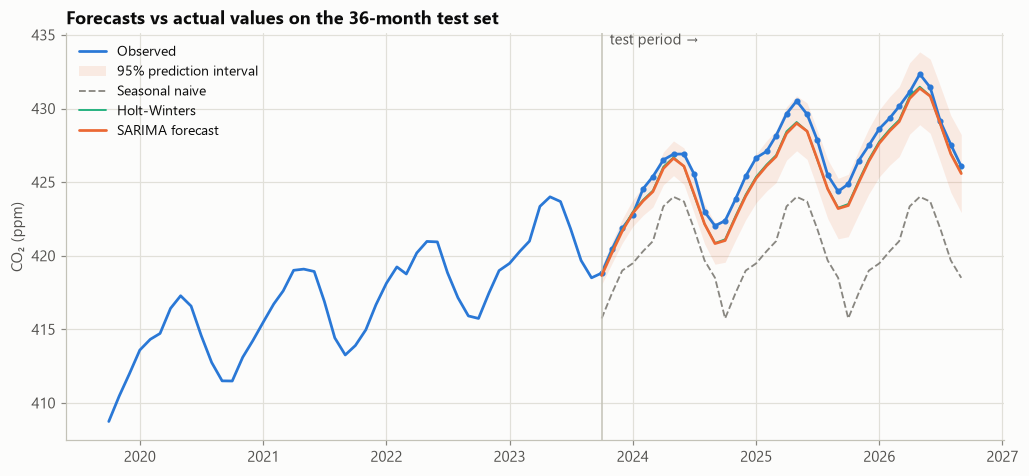

In [37]:
fig, ax = plt.subplots(figsize=(11, 4.8))
observed = y[y.index >= test.index.min() - pd.DateOffset(years=4)]
ax.plot(observed.index, observed, color=COLORS["history"], label="Observed")
ax.plot(test.index, test, "o", color=COLORS["history"], markersize=3)
ax.fill_between(sarima_ci.index, sarima_ci.iloc[:, 0], sarima_ci.iloc[:, 1],
                color=COLORS["forecast"], alpha=0.12, linewidth=0, label="95% prediction interval")
ax.plot(baselines["Seasonal naive"].index, baselines["Seasonal naive"], color=COLORS["muted"],
        linestyle="--", linewidth=1.2, label="Seasonal naive")
ax.plot(baselines["Holt-Winters"].index, baselines["Holt-Winters"], color=COLORS["third"],
        linewidth=1.2, label="Holt-Winters")
ax.plot(sarima_pred.index, sarima_pred, color=COLORS["forecast"], label="SARIMA forecast", zorder=5)
ax.axvline(test.index.min(), color=COLORS["axis"], linewidth=1)
ax.text(test.index.min(), ax.get_ylim()[1], "  test period →", va="top", color=COLORS["ink2"])
ax.set(title="Forecasts vs actual values on the 36-month test set", ylabel="CO₂ (ppm)")
ax.legend(loc="upper left")
savefig(fig, "16_test_forecast")
plt.show()

**Result**
- SARIMA forecasts three years ahead with an average error of under 1 ppm — a **MAPE of about 0.2%** — and
  almost all actual values fall inside its 95% prediction interval.
- It is far better than the seasonal naive baseline (which ignores the trend) and better than seasonal naive + drift.
- **Holt–Winters performs about equally well** — slightly lower error on this particular test window (by about
  0.07 ppm), and the two forecast lines almost overlap. We keep SARIMA because it is the Box–Jenkins model this course
  focuses on, its residuals pass every diagnostic, and it gives statistically grounded prediction intervals.
  The two methods agreeing so closely is good evidence that the forecast is reliable.

### 10.6 Final model on the full data and future forecast
For deployment, the selected model is re-fitted on **all** 823 months and used to forecast the next 10 years.

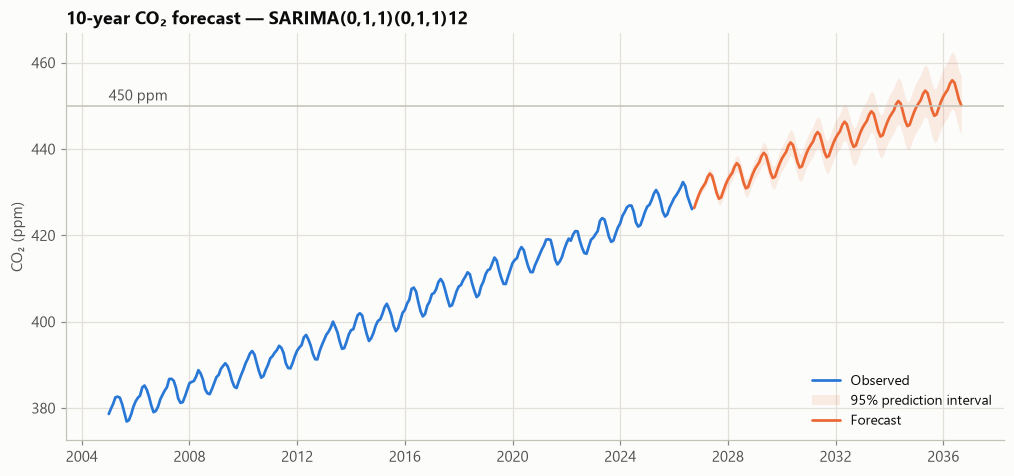

Forecast first reaches 450 ppm in: April 2034


,Forecast yearly mean CO₂ (ppm)
2027,431.39
2028,433.79
2029,436.19
2030,438.59
2031,441.00
2032,443.40
2033,445.80
2034,448.20
2035,450.60
2036,453.37


In [38]:
final_model = fit_sarima(y, ORDER, SEASONAL_ORDER)
future = final_model.get_forecast(120)
future_mean, future_ci = future.predicted_mean, future.conf_int(alpha=0.05)

fig, ax = plt.subplots(figsize=(11, 4.8))
history = y[y.index >= "2005-01-01"]
ax.plot(history.index, history, color=COLORS["history"], label="Observed")
ax.fill_between(future_ci.index, future_ci.iloc[:, 0], future_ci.iloc[:, 1],
                color=COLORS["forecast"], alpha=0.12, linewidth=0, label="95% prediction interval")
ax.plot(future_mean.index, future_mean, color=COLORS["forecast"], label="Forecast")
ax.axhline(450, color=COLORS["axis"], linewidth=1)
ax.text(history.index[0], 450.5, "450 ppm", color=COLORS["ink2"], va="bottom")
ax.set(title=f"10-year CO₂ forecast — {best['Model']}", ylabel="CO₂ (ppm)")
ax.legend(loc="lower right")
savefig(fig, "17_future_forecast")
plt.show()

crossing = future_mean[future_mean >= 450].index.min()
print(f"Forecast first reaches 450 ppm in: {crossing:%B %Y}" if pd.notna(crossing) else "Stays below 450 ppm")
yearly_forecast = future_mean.groupby(future_mean.index.year).mean()
yearly_forecast[yearly_forecast.index > y.index.max().year].round(2).to_frame("Forecast yearly mean CO₂ (ppm)")

## Step 11 — Deploying the Model

The selected model is deployed as an interactive **Streamlit** web application.

| File | Purpose |
|---|---|
| `src/ts_utils.py` | shared code: data loading, ADF/KPSS reports, model fitting, error metrics |
| `train.py` | re-fits SARIMA(0,1,1)(0,1,1)₁₂ on the full data, checks it on a 36-month hold-out, saves `models/sarima_co2.pkl` and `models/model_info.json` |
| `app.py` | Streamlit app: choose the forecast horizon and confidence level, view the interactive forecast chart, KPI tiles (latest CO₂, forecast, when 450 ppm is reached), decomposition and model diagnostics, and download the forecast as CSV |

**Run locally**
```bash
python train.py            # add --refresh to download the latest NOAA data first
streamlit run app.py
```

**Publish online (free):** push the project to GitHub → <https://share.streamlit.io> → *New app* → select the
repository and `app.py` → *Deploy*. Streamlit Community Cloud installs `requirements.txt` and gives a public link.

## Conclusion

- Monthly Mauna Loa CO₂ (March 1958 – latest month) shows a strong, **accelerating upward trend** and a
  regular **12-month seasonal cycle** (peak in May, lowest in September–October).
- The series has no missing values in the target column; missing-value techniques were demonstrated on the
  weekly CO₂ data, where interpolation clearly beat forward fill and mean fill.
- The ADF and KPSS tests show the original series is non-stationary; **one regular and one seasonal difference**
  (d = 1, D = 1) make it stationary.
- ACF/PACF analysis and a 36-model AIC/BIC grid search both lead to **SARIMA(0,1,1)(0,1,1)₁₂**, with white-noise
  residuals and a test-set **MAPE of about 0.2%**.
- If the current growth rate continues, the model expects the monthly CO₂ value to first cross **450 ppm in
  about 2034** (at the May seasonal peak), and the yearly average to pass 450 ppm a year later.

**Limitations and future work**
- SARIMA extrapolates the recent growth rate; it cannot know about future changes in emissions (policy,
  economic shocks). Adding explanatory variables (e.g. global emissions) with **SARIMAX** could address this.
- Prediction intervals widen with the horizon — long-range forecasts should be read as "if current trends continue".
- Other methods (Holt–Winters, Prophet, LSTM) could be compared in more depth; Holt–Winters already performs on par.